In [1]:
from typing import Annotated, Literal

from dotenv import load_dotenv
from langchain.mcp import MCPAdapter
from langchain_core.messages import AnyMessage, HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from pydantic import BaseModel, Field


/var/folders/mn/8mt68f1n2tl7s8y2nlzb6xvc0000gn/T/ipykernel_55233/2816453493.py:4: LangChainBetaWarning: `langchain.mcp` is in beta. It is actively being worked on, so the API may change.
  from langchain.mcp import MCPAdapter


In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [4]:
class Classification(BaseModel):
    category: Literal["career", "relationships", "education", "health", "general"] = (
        Field(description="Defines category field of question asked by user")
    )

In [5]:
class ChatState(BaseModel):
    # The current user request; kept separate from tool-call messages.
    question: HumanMessage

    messages: Annotated[list[AnyMessage], add_messages] = Field(
        default_factory=list,
        description="Research-agent and tool-call messages for the current question",
    )
    category: str | None = "Unclassified"
    skill_instructions: str | None = "None"
    needs_tools: bool = False

    # Snapshot loaded from the authoritative user-profile database.
    user_id: str
    birth_profile_version: int
    dob: str
    birth_time: str
    birth_place: str

    research_findings: list[AnyMessage] = Field(
        default_factory=list, description="Research findings and tool output blocks"
    )
    final_answer: list[AnyMessage] = Field(
        default_factory=list, description="Final Polished Output to User"
    )

In [6]:
classifier_llm = model.with_structured_output(Classification)


def classify_node(state: ChatState):
    question = state.question.content
    print("Question", question)
    result = classifier_llm.invoke(f""" Classify the user's astrology question.
      Question {question}""")

    return {"category": result.category}

In [7]:
from aistrology_langgraph_skeleton.skills.registry import load_skill


def load_skill_node(state: ChatState):
    skill = load_skill(state.category)
    return {"skill_instructions": skill}

In [8]:
mcpConfig = {
    "mcpServers": {
        "vedastro": {
            "type": "sse",
            "url": "https://mcp.vedastro.org/api/mcp/public",
            "headers": {"x-api-key": "demo"},
        }
    }
}

# Getting Tools
async with MCPAdapter(mcpConfig) as adapter:
    tools = await adapter.list_tools()


In [9]:
RESEARCH_SYSTEM_PROMPT = """
    You are AIstrology's research agent.

    Follow the domain-specific instructions below.

    {skill}

    User context:
    {user_context}

    Use tools when necessary to obtain accurate
    astrological calculations or retrieve knowledge.

    Return verified findings for the final-answer agent, rather than addressing
    the user directly.

    Never invent birth-chart calculations.
    """
llm_with_tools = model.bind_tools(tools)


def format_user_context(state: ChatState) -> str:
    return (
        f"user_id={state.user_id}\n"
        f"birth_profile_version={state.birth_profile_version}\n"
        f"dob={state.dob}\n"
        f"birth_time={state.birth_time}\n"
        f"birth_place={state.birth_place}"
    )


async def research_node(state: ChatState):
    prompt = RESEARCH_SYSTEM_PROMPT.format(
        skill=state.skill_instructions,
        user_context=format_user_context(state),
    )
    messages = [SystemMessage(content=prompt), state.question, *state.messages]

    response = await llm_with_tools.ainvoke(messages)

    return {
        "messages": [response],
        "research_findings": [response],
        "needs_tools": bool(response.tool_calls),
    }

In [10]:
tool_node = ToolNode(tools)

In [11]:
def research_findings_text(state: ChatState) -> str:
    def content_as_text(message: AnyMessage) -> str:
        if isinstance(message.content, str):
            return message.content
        return "\n".join(
            block["text"]
            for block in message.content
            if isinstance(block, dict) and block.get("type") == "text"
        )

    return "\n\n".join(
        text
        for finding in state.research_findings
        if (text := content_as_text(finding))
    )


def chat_node(state: ChatState):
    SYSTEM_PROMPT = """You are Aistrology, a helpful and thoughtful chat assistant.
    Use the following user context when answering astrology questions:
    {user_context}

    Use these verified research findings as source material:
    {research_findings}
    Understand the user's request, reason carefully in private, and give a clear,
    direct final answer. Do not reveal hidden chain-of-thought or private reasoning.
    If information is uncertain, say so plainly."""

    prompt = SYSTEM_PROMPT.format(
        user_context=format_user_context(state),
        research_findings=research_findings_text(state),
    )
    response = model.invoke([SystemMessage(content=prompt), state.question])

    return {"final_answer": [response]}


In [12]:
def route_after_research(state: ChatState):
    if state.needs_tools:
        return "tools"
    return "chat"

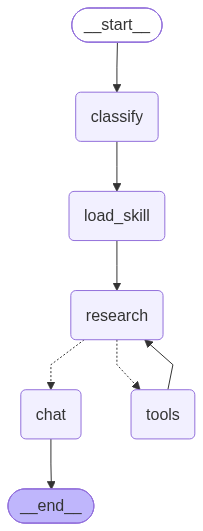

In [13]:
# Graph
graph = StateGraph(ChatState)
graph.add_node("chat", chat_node)
graph.add_node("classify", classify_node)
graph.add_node("load_skill", load_skill_node)
graph.add_node("tools", tool_node)
graph.add_node("research", research_node)
graph.add_edge(START, "classify")
graph.add_edge("classify", "load_skill")
graph.add_edge("load_skill", "research")
graph.add_conditional_edges(
    "research", route_after_research, {"tools": "tools", "chat": "chat"}
)
graph.add_edge("tools", "research")
graph.add_edge("chat", END)

# Use a production checkpointer backed by your database in the application.
workflow = graph.compile(checkpointer=MemorySaver())
workflow

In [14]:
# Load this profile snapshot from your database; it remains authoritative.
birth_profile = {
    "user_id": "user_123",
    "birth_profile_version": 1,
    "dob": "2002-02-08",
    "birth_time": "16:10",
    "birth_place": "Jaipur, Rajasthan, India",
}
thread_id = (
    f"{birth_profile['user_id']}:birth-profile:{birth_profile['birth_profile_version']}"
)

await workflow.ainvoke(
    {
        "question": HumanMessage(
            content="I am in Software Engineering field, when will I get a good job?"
        ),
        **birth_profile,
    },
    config={"configurable": {"thread_id": thread_id}},
)

Question I am in Software Engineering field, when will I get a good job?


Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is not supported in schema, ignoring
Key 'additionalProperties' is not supported in schema, ignoring
Key '$schema' is

{'question': HumanMessage(content='I am in Software Engineering field, when will I get a good job?', additional_kwargs={}, response_metadata={}),
 'messages': [AIMessage(content=[], additional_kwargs={'function_call': {'name': 'get_dasa_at_time', 'arguments': '{"birth_time": "16:10", "location_name": "Jaipur, Rajasthan, India", "check_date": "15/06/2025", "query_text": "career prospects and job timing for software engineering role", "birth_date": "08/02/2002"}'}, '__gemini_function_call_thought_signatures__': {'call_827564': 'EnMKcQFpFH0TX9M/OdI2zk+xEZoqVCq4WLF9Lt4Wi47bvKvUcVrNNJO4OoRLM2CZM7HUceTDmiO/GQCwbWv8wyeyw/o+gU2HU37RCFQTl2Js35TiqRg2lICNPldJzB5+TSZi7joKL8fTPRN5P0xqVTqJdSck'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a18755-7a8e-77a4-a20e-b91c233eb304-0', tool_calls=[{'name': 'get_dasa_at_time', 'args': {'birth_time': '16:10', 'location_name': 'Jaipur, Rajasthan, Indi